**Dimensionality Reduction using PCA (Principal Component Analysis)**

In [48]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

**1. Load Dataset**

In [50]:
df = pd.read_csv('/content/drive/MyDrive/Machine Learning/wine_dataset.csv')
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,target_name
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0


**2. Data Preprocessing**

In [51]:
X = df.drop(['target', 'target_name'], axis=1)
y = df['target']

In [52]:
print("\nNumber of features:", X.shape[1])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


Number of features: 13


In [53]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

**3. Apply PCA**

**■ Initialize a PCA model.**

**■ Fit PCA to the scaled data.**

**■ Analyze the explained_variance_ratio_ to understand how much
variance each principal component captures.**

In [54]:
pca = PCA()
pca.fit(X_train_scaled)

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nCumulative Explained Variance:")
print(np.cumsum(pca.explained_variance_ratio_))


Explained Variance Ratio:
[0.35792104 0.19270671 0.11019835 0.07272276 0.06721919 0.05131943
 0.04377423 0.02500853 0.0227943  0.01877102 0.01781765 0.01256721
 0.00717958]

Cumulative Explained Variance:
[0.35792104 0.55062776 0.66082611 0.73354887 0.80076806 0.85208748
 0.89586171 0.92087024 0.94366454 0.96243556 0.98025321 0.99282042
 1.        ]


**■ Plot the cumulative explained variance to determine the number of components to retain.**

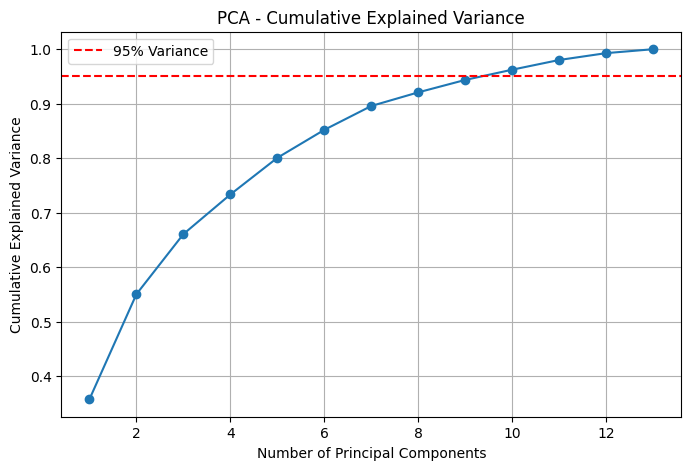

In [55]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),
    np.cumsum(pca.explained_variance_ratio_),
    marker='o'
)

plt.axhline(y=0.95, color='red', linestyle='--',
            label='95% Variance')

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Cumulative Explained Variance")
plt.legend()
plt.grid()
plt.show()

**4. Retain Top Components**

In [56]:
pca_2 = PCA(n_components=2)

X_train_pca = pca_2.fit_transform(X_train_scaled)
X_test_pca = pca_2.transform(X_test_scaled)

print("\nOriginal Features:", X_train_scaled.shape[1])
print("Reduced Features:", X_train_pca.shape[1])

print("Variance Retained:",
      round(sum(pca_2.explained_variance_ratio_) * 100, 2), "%")


Original Features: 13
Reduced Features: 2
Variance Retained: 55.06 %


**5. Visualize Data in 2D**

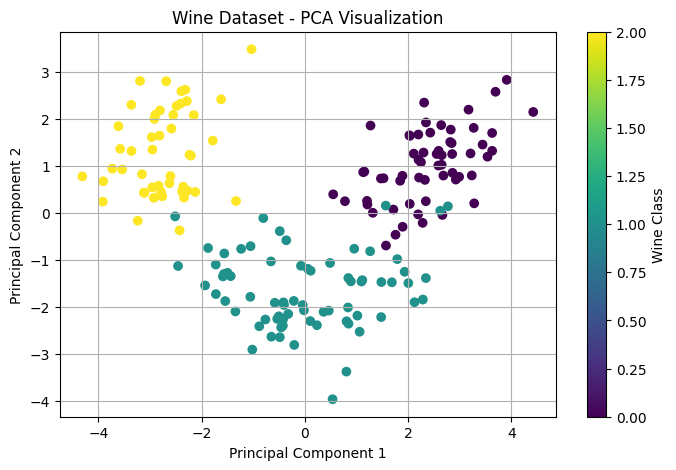

In [57]:
X_all_scaled = scaler.transform(X)
X_all_pca = pca_2.transform(X_all_scaled)

plt.figure(figsize=(8, 5))

scatter = plt.scatter(
    X_all_pca[:, 0],
    X_all_pca[:, 1],
    c=y,
    cmap='viridis'
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Wine Dataset - PCA Visualization")
plt.colorbar(scatter, label="Wine Class")
plt.grid()
plt.show()

**6. Train Classifier on Reduced Data and Compare**

In [58]:
model_original = LogisticRegression(max_iter=2000)

model_original.fit(X_train_scaled, y_train)

y_pred_original = model_original.predict(X_test_scaled)

accuracy_original = accuracy_score(y_test, y_pred_original)

In [59]:
model_pca = LogisticRegression(max_iter=2000)

model_pca.fit(X_train_pca, y_train)

y_pred_pca = model_pca.predict(X_test_pca)

accuracy_pca = accuracy_score(y_test, y_pred_pca)

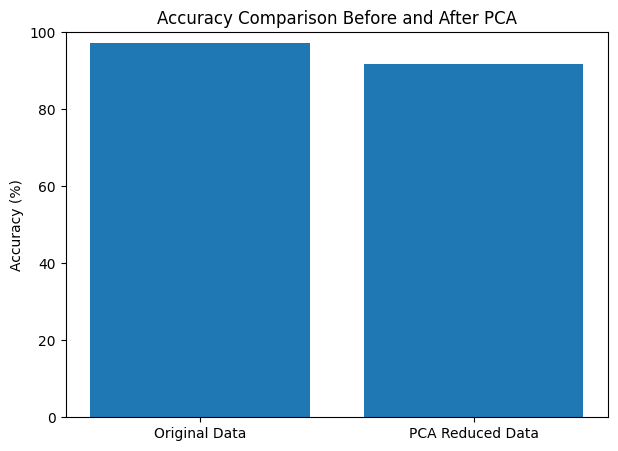

In [60]:
plt.figure(figsize=(7, 5))

plt.bar(
    ["Original Data", "PCA Reduced Data"],
    [accuracy_original * 100, accuracy_pca * 100]
)

plt.ylabel("Accuracy (%)")
plt.title("Accuracy Comparison Before and After PCA")
plt.ylim(0, 100)
plt.show()


In [61]:
print("\nOriginal Data Accuracy:",
      round(accuracy_original * 100, 2), "%")

print("PCA Reduced Data Accuracy:",
      round(accuracy_pca * 100, 2), "%")


Original Data Accuracy: 97.22 %
PCA Reduced Data Accuracy: 91.67 %


In [62]:
pca_95 = PCA(n_components=0.95)

X_train_95 = pca_95.fit_transform(X_train_scaled)
X_test_95 = pca_95.transform(X_test_scaled)

print("\nComponents Needed for 95% Variance:",
      pca_95.n_components_)

print("Variance Retained:",
      round(sum(pca_95.explained_variance_ratio_) * 100, 2), "%")


Components Needed for 95% Variance: 10
Variance Retained: 96.24 %
